## W2-DSA-03: Feature Drift Metrics (PSI/KS)

For this task we checked whether the transaction data changes over time. We used creditcard_clean.csv (283,726 rows, 473 of them fraud), sorted by Time. The data covers about 48 hours.

The first 24 hours (144,236 rows) are the reference period. We compared it against four 6-hour windows from the second day: 24-30h (11,546 rows), 30-36h (35,746), 36-42h (49,390) and 42-48h (42,808). We picked 6 hours so there would be enough windows to see a trend without making each one too small.

Transaction volume and behaviour change between night and day, so comparing a night window with a full-day reference can look like drift when it isn't. To check this, we also compared each window with the same hours of the first day (for example 24-30h against 0-6h).

We calculated PSI and the KS statistic for all 29 features, leaving out Time (it always increases) and Class. The plots focus on Amount, the six features with the strongest fraud signal (V17, V14, V12, V10, V11, V4) and the features with the highest PSI.

For PSI we used the usual rule of thumb: below 0.1 means stable, 0.1 to 0.25 means moderate change, and above 0.25 means a significant shift. We report the KS statistic and not its p-value, because with this many rows the p-value comes out close to zero even for tiny differences.

In [11]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import ks_2samp

In [12]:
assert os.path.exists('creditcard_clean.csv'), "creditcard_clean.csv not found - upload it or re-run the cleaning cell"

df = pd.read_csv('creditcard_clean.csv').sort_values('Time').reset_index(drop=True)
FEATURES = ['Amount', 'V17', 'V14', 'V12', 'V10', 'V11', 'V4']
H = 3600
ref = df[df.Time < 24 * H]
windows = {f'{a}-{a+6}h': df[(df.Time >= a * H) & (df.Time < (a + 6) * H)]
           for a in [24, 30, 36, 42]}

print("Total rows:", len(df), "| Fraud:", df.Class.sum())
print("Reference (0-24h):", len(ref))
for k, w in windows.items():
    print(k, len(w))

AssertionError: creditcard_clean.csv not found - upload it or re-run the cleaning cell

In [ ]:
def psi(ref_s, cur_s, bins=10):
    edges = np.unique(np.quantile(ref_s, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref_s, edges)[0] / len(ref_s)
    c = np.histogram(cur_s, edges)[0] / len(cur_s)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return np.sum((c - r) * np.log(c / r))

ALL = [c for c in df.columns if c not in ('Time', 'Class')]

psi_all = pd.DataFrame({wn: [psi(ref[f], w[f]) for f in ALL]
                        for wn, w in windows.items()}, index=ALL)
ks_all = pd.DataFrame({wn: [ks_2samp(ref[f], w[f]).statistic for f in ALL]
                       for wn, w in windows.items()}, index=ALL)

psi_all.to_csv('drift_psi_all.csv'); ks_all.to_csv('drift_ks_all.csv')

# selected features, used by the plotting cells
psi_tbl, ks_tbl = psi_all.loc[FEATURES], ks_all.loc[FEATURES]

print("PSI - selected features"); display(psi_tbl.round(3))
print("KS statistic - selected features"); display(ks_tbl.round(3))

print("Top 10 features by max PSI (all features)")
display(psi_all.assign(max_PSI=psi_all.max(axis=1))
        .sort_values('max_PSI', ascending=False).head(10).round(3))

PSI - selected features


,24-30h,30-36h,36-42h,42-48h
Amount,0.083,0.003,0.003,0.023
V17,0.083,0.046,0.048,0.062
V14,1.125,0.072,0.072,0.081
V12,1.660,0.026,0.062,0.080
V10,0.194,0.084,0.086,0.074
V11,0.059,0.318,0.470,0.481
V4,0.158,0.179,0.191,0.251


KS statistic - selected features


,24-30h,30-36h,36-42h,42-48h
Amount,0.129,0.023,0.021,0.068
V17,0.122,0.090,0.093,0.104
V14,0.444,0.084,0.098,0.111
V12,0.570,0.063,0.059,0.069
V10,0.169,0.084,0.073,0.058
V11,0.095,0.176,0.200,0.200
V4,0.113,0.168,0.175,0.198


Top 10 features by max PSI (all features)


,24-30h,30-36h,36-42h,42-48h,max_PSI
V12,1.660,0.026,0.062,0.080,1.660
V1,1.570,1.597,1.527,1.609,1.609
V3,1.003,1.387,1.529,1.498,1.529
V28,1.224,1.090,1.027,1.013,1.224
V9,1.151,0.056,0.049,0.062,1.151
V14,1.125,0.072,0.072,0.081,1.125
V15,0.985,0.349,0.375,0.396,0.985
V13,0.932,0.003,0.022,0.020,0.932
V5,0.574,0.360,0.325,0.337,0.574
V25,0.434,0.379,0.430,0.517,0.517


In [ ]:
same_hour = df[df.Time < 6 * H]   # Day 1, hours 0-6 (same time of day)
w = windows['24-30h']
cols = ['V12', 'V14', 'V9', 'V13']

chk = pd.DataFrame({
    'vs full-day ref (0-24h)': [psi(ref[f], w[f]) for f in cols],
    'vs same hours Day 1 (0-6h)': [psi(same_hour[f], w[f]) for f in cols],
}, index=cols)
display(chk.round(3))

,vs full-day ref (0-24h),vs same hours Day 1 (0-6h)
V12,1.660,0.007
V14,1.125,0.042
V9,1.151,0.061
V13,0.932,0.014


## W2-DSA-04: Drift Visualizations

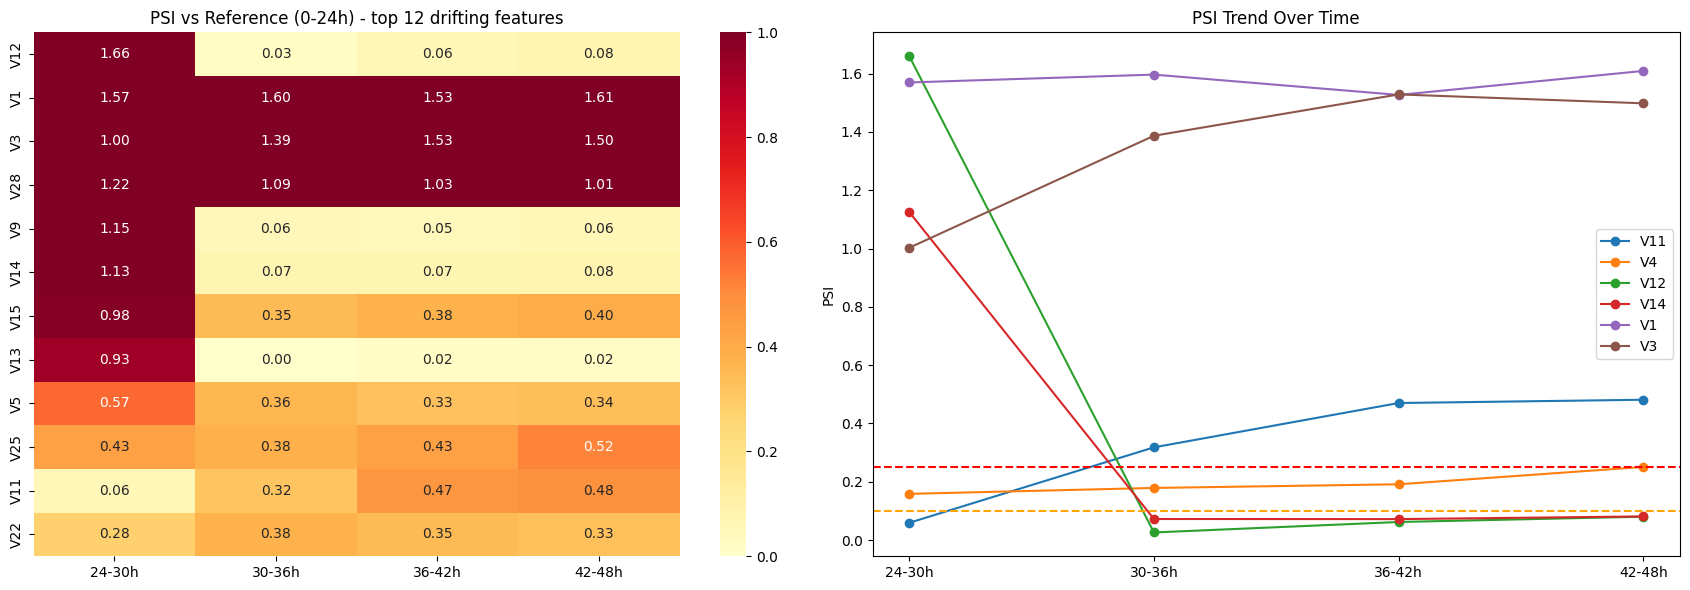

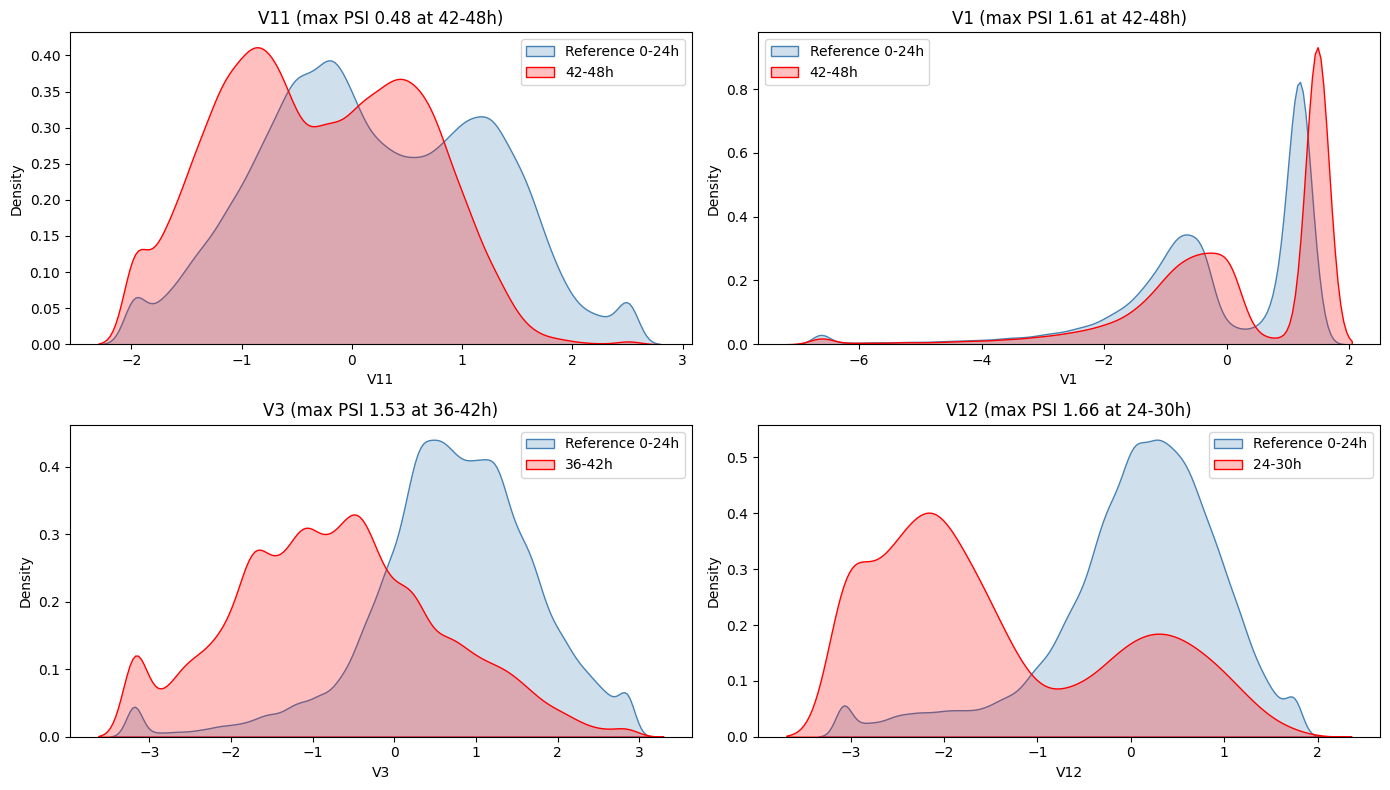

In [ ]:
top = psi_all.max(axis=1).sort_values(ascending=False).head(12).index

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(psi_all.loc[top], annot=True, fmt='.2f', cmap='YlOrRd', ax=ax[0], vmin=0, vmax=1)
ax[0].set_title("PSI vs Reference (0-24h) - top 12 drifting features")

for f in ['V11', 'V4', 'V12', 'V14', 'V1', 'V3']:
    ax[1].plot(psi_all.columns, psi_all.loc[f], marker='o', label=f)
ax[1].axhline(0.1, ls='--', c='orange'); ax[1].axhline(0.25, ls='--', c='red')
ax[1].set_title("PSI Trend Over Time"); ax[1].set_ylabel("PSI"); ax[1].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for a, f in zip(axes.ravel(), ['V11', 'V1', 'V3', 'V12']):
    wn = psi_all.loc[f].idxmax()
    lo, hi = ref[f].quantile([0.01, 0.99])
    sns.kdeplot(ref[f].clip(lo, hi), ax=a, label='Reference 0-24h', fill=True, color='steelblue')
    sns.kdeplot(windows[wn][f].clip(lo, hi), ax=a, label=wn, fill=True, color='red')
    a.set_title(f"{f} (max PSI {psi_all.loc[f].max():.2f} at {wn})"); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
matched = {wn: df[(df.Time >= (a - 24) * H) & (df.Time < (a - 18) * H)]
           for wn, a in zip(windows, [24, 30, 36, 42])}

psi_matched = pd.DataFrame({wn: [psi(matched[wn][f], windows[wn][f]) for f in ALL]
                            for wn in windows}, index=ALL)
psi_matched.to_csv('drift_psi_matched.csv')

print("Matched-hour PSI - selected features")
display(psi_matched.loc[FEATURES].round(3))
print("Top 10 by max PSI (matched-hour)")
display(psi_matched.assign(max_PSI=psi_matched.max(axis=1))
        .sort_values('max_PSI', ascending=False).head(10).round(3))

Matched-hour PSI - selected features


,24-30h,30-36h,36-42h,42-48h
Amount,0.025,0.010,0.004,0.005
V17,0.090,0.044,0.038,0.057
V14,0.042,0.083,0.108,0.103
V12,0.007,0.015,0.013,0.011
V10,0.071,0.082,0.088,0.098
V11,0.273,0.336,0.393,0.381
V4,0.149,0.181,0.205,0.256


Top 10 by max PSI (matched-hour)


,24-30h,30-36h,36-42h,42-48h,max_PSI
V1,1.592,1.582,1.518,1.625,1.625
V3,1.282,1.376,1.503,1.464,1.503
V28,0.990,1.134,0.994,1.078,1.134
V15,0.342,0.323,0.396,0.513,0.513
V25,0.425,0.402,0.425,0.510,0.510
V11,0.273,0.336,0.393,0.381,0.393
V22,0.385,0.332,0.348,0.328,0.385
V5,0.383,0.342,0.354,0.360,0.383
V26,0.373,0.189,0.218,0.241,0.373
V23,0.267,0.210,0.205,0.256,0.267


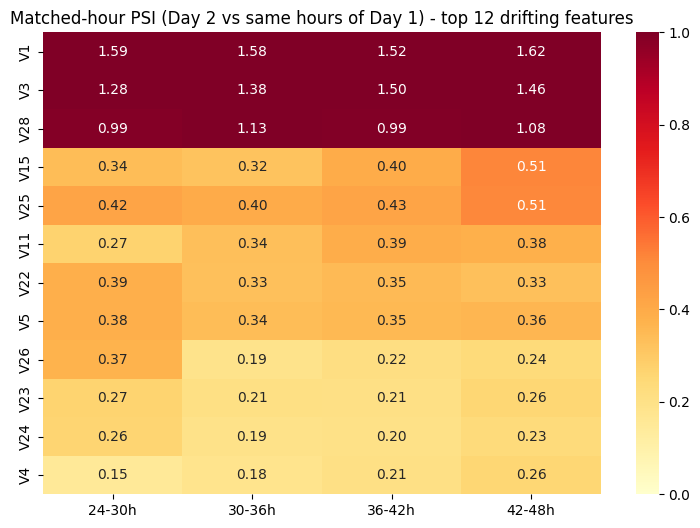

In [ ]:
top = psi_matched.max(axis=1).sort_values(ascending=False).head(12).index
plt.figure(figsize=(9, 6))
sns.heatmap(psi_matched.loc[top], annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1)
plt.title("Matched-hour PSI (Day 2 vs same hours of Day 1) - top 12 drifting features")
plt.show()


## W2-DSA-04: Findings

1. Most of the drift that shows up in the first window is just time of day. V12, V14, V9 and V13 look like they drift a lot in 24-30h (PSI 0.93 to 1.66) when compared with the full first day, but when compared with the same hours of day one the PSI is only 0.007 to 0.061.

2. V1, V3 and V28 have real, large drift. Even with the matched-hour comparison, their PSI stays between about 0.99 and 1.63 in every window, far above the 0.25 line. These are the biggest shifts in the dataset.

3. V11 and V4 are also drifting, and they matter more because they are strong fraud-signal features. V11 stays above 0.25 in all four windows (0.273 to 0.393), and V4 climbs from 0.149 to 0.256.

4. Amount and V17 are stable. Their matched-hour PSI never goes above 0.09, so transaction amounts are not drifting.

5. For monitoring, we suggest keeping an eye on V1, V3, V28, V11 and V4. The drift check should compare against the same hours of the day, or use a reference that accounts for hour of day, otherwise it will raise false alarms at night.

A few limits to keep in mind. We only have two days of data, so we can't say whether this is a lasting trend or just a difference between day one and day two. PSI tells us the feature values changed, not that a model would perform worse. Because V1 to V28 are anonymized, we also can't say why they changed.